In [1]:
import numpy as np
import pylab
from qiskit.quantum_info import SparsePauliOp
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SPSA, SLSQP, COBYLA
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_ibm_runtime.fake_provider import FakeLimaV2
from qiskit.circuit.library import n_local
from qiskit import transpile

H2_op = SparsePauliOp.from_list(
    [
        ("II", -1.052373245772859),
        ("IZ", 0.39793742484318045),
        ("ZI", -0.39793742484318045),
        ("ZZ", -0.01128010425623538),
        ("XX", 0.18093119978423156),
    ]
)

ref_value = -1.85728
print(f"Target Energy: {ref_value}")

Target Energy: -1.85728


In [2]:
backend = FakeLimaV2()

ansatz = n_local(2, rotation_blocks="ry", entanglement_blocks="cz")

transpiled_ansatz = transpile(ansatz, backend=backend, optimization_level=3)

print("Circuit transpiled for FakeLimaV2.")

Circuit transpiled for FakeLimaV2.


In [3]:
noisy_estimator = AerEstimator.from_backend(backend)

noisy_estimator.options.default_precision = 0.01

In [4]:
import time

def run_vqe_experiment(optimizer, label):
    print(f"\nStarting {label} optimization...")

    counts = []
    values = []

    def store_intermediate_result(eval_count, parameters, mean, std):
        counts.append(eval_count)
        values.append(mean)
        if eval_count % 25 == 0:
            print(f"  {label} Step {eval_count}: Energy {mean:.5f}")

    vqe = VQE(
        estimator=noisy_estimator, 
        ansatz=transpiled_ansatz, 
        optimizer=optimizer, 
        callback=store_intermediate_result
    )

    start_time = time.time()
    result = vqe.compute_minimum_eigenvalue(operator=H2_op)
    end_time = time.time()
    
    print(f"Done! Final Energy: {result.eigenvalue.real:.5f}")
    print(f"Time taken: {end_time - start_time:.2f}s")
    
    return counts, values, result.eigenvalue.real

In [5]:
spsa = SPSA(maxiter=125)

counts_spsa, values_spsa, energy_spsa = run_vqe_experiment(spsa, "SPSA")


Starting SPSA optimization...
  SPSA Step 25: Energy -0.99784
  SPSA Step 50: Energy -0.79388
  SPSA Step 75: Energy -1.80096
  SPSA Step 100: Energy -1.80829
  SPSA Step 125: Energy -1.79581
  SPSA Step 150: Energy -1.80987
  SPSA Step 175: Energy -1.79164
  SPSA Step 200: Energy -1.83330
  SPSA Step 225: Energy -1.82100
  SPSA Step 250: Energy -1.79934
  SPSA Step 275: Energy -1.84920
  SPSA Step 300: Energy -1.82242
Done! Final Energy: -1.83135
Time taken: 4.47s


In [6]:
slsqp = SLSQP(maxiter=125)

counts_slsqp, values_slsqp, energy_slsqp = run_vqe_experiment(slsqp, "SLSQP")


Starting SLSQP optimization...
  SLSQP Step 25: Energy -1.12844
  SLSQP Step 50: Energy -0.51760
  SLSQP Step 75: Energy -1.81668
  SLSQP Step 100: Energy -1.24297
  SLSQP Step 125: Energy -0.89526
  SLSQP Step 150: Energy -1.12426
  SLSQP Step 175: Energy -0.98114
  SLSQP Step 200: Energy -0.36947
  SLSQP Step 225: Energy -1.47721
  SLSQP Step 250: Energy -1.51523
  SLSQP Step 275: Energy -0.63850
  SLSQP Step 300: Energy -0.64761
  SLSQP Step 325: Energy -1.01903
  SLSQP Step 350: Energy -0.91131
  SLSQP Step 375: Energy -0.56534
  SLSQP Step 400: Energy -0.64135
  SLSQP Step 425: Energy -1.26354
  SLSQP Step 450: Energy -0.90409
  SLSQP Step 475: Energy -1.12794
  SLSQP Step 500: Energy -0.98169
  SLSQP Step 525: Energy -1.22493
  SLSQP Step 550: Energy -1.10091
  SLSQP Step 575: Energy -1.09145
  SLSQP Step 600: Energy -1.07639
  SLSQP Step 625: Energy -1.08409
  SLSQP Step 650: Energy -1.08601
  SLSQP Step 675: Energy -1.07558
  SLSQP Step 700: Energy -1.10052
Done! Final Energy:

In [7]:
cobyla = COBYLA(maxiter=125)

counts_cobyla, values_cobyla, energy_cobyla = run_vqe_experiment(cobyla, "COBYLA")


Starting COBYLA optimization...
  COBYLA Step 25: Energy -1.81329
  COBYLA Step 50: Energy -1.81987
Done! Final Energy: -1.84859
Time taken: 3.00s


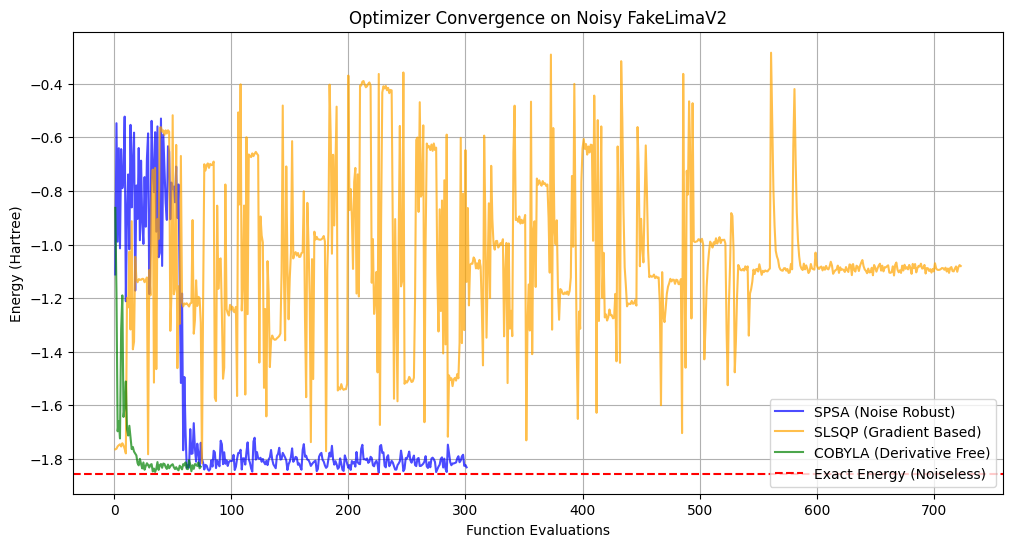

In [8]:
pylab.rcParams["figure.figsize"] = (12, 6)

pylab.plot(counts_spsa, values_spsa, label="SPSA (Noise Robust)", color='blue', alpha=0.7)

pylab.plot(counts_slsqp, values_slsqp, label="SLSQP (Gradient Based)", color='orange', alpha=0.7)

pylab.plot(counts_cobyla, values_cobyla, label="COBYLA (Derivative Free)", color='green', alpha=0.7)

pylab.axhline(y=ref_value, color='red', linestyle='--', label="Exact Energy (Noiseless)")

pylab.xlabel("Function Evaluations")
pylab.ylabel("Energy (Hartree)")
pylab.title("Optimizer Convergence on Noisy FakeLimaV2")
pylab.legend()
pylab.grid(True)
pylab.show()